# Funzioni del modello

In [ ]:
import os
from collections.abc import Callable

import numpy as np
import numpy.typing as npt
import matplotlib.pyplot as plt

# Float NumPY vector
type Array = npt.NDArray[np.float64]

# Sessions vector
type Sessions = npt.NDArray[np.int_]

# Grafici

Cartella in cui vengono salvati i pdf e funzione che completa e salva un grafico.

In [ ]:
FUNCTIONS_DIR: str = os.path.join("..", "tesi", "images", "functions")
os.makedirs(FUNCTIONS_DIR, exist_ok = True)


def save_plot(
        name: str,
        title: str,
        x_label: str,
        y_label: str,
        legend_position: str
    ) -> None:
    plt.xlabel(x_label)
    plt.ylabel(y_label)

    plt.title(title)

    plt.grid(True, linestyle = "--", alpha = 0.6)

    plt.legend(loc = legend_position)

    plt.tight_layout()

    plt.savefig(os.path.join(FUNCTIONS_DIR, name + ".pdf"), dpi = 300)

    plt.show()
    
    plt.close()

# Funzione di crescita

In [ ]:
def mu(x: Array, omega: float, sigma: float) -> Array:
    return omega * np.exp(- (x ** 2) / (2 * sigma ** 2))


x: Array = np.linspace(0, 1, 1000)

## Andamento generale

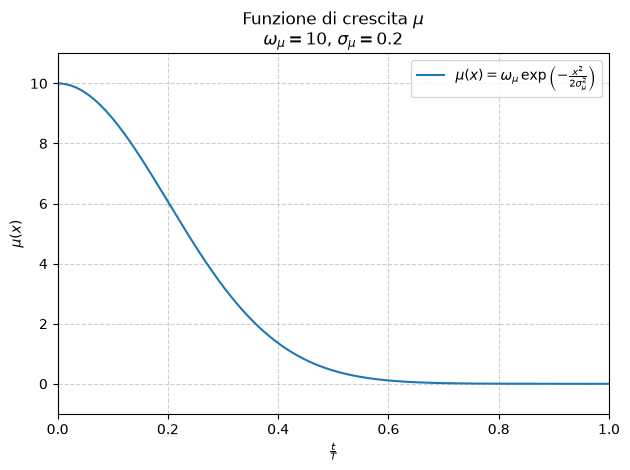

In [ ]:
omega: float = 10
sigma: float = 0.2
y: Array = mu(x, omega, sigma)

plt.plot(x, y, label = r'$\mu(x) = \omega_\mu \, \exp\left(-\frac{x^2}{2 \sigma_\mu^2}\right)$')

plt.xlim(0, 1)
plt.ylim(-1, omega + 1)

save_plot(
    "mu",
    r"Funzione di crescita $\mu$" + "\n" + r"$\omega_\mu = " + str(omega) + r"$, $\sigma_\mu = " + str(sigma) + r"$",
    r"$\frac{t}{T}$",
    r"$\mu(x)$",
    "upper right"
)

## Effetto di $\sigma_\mu$

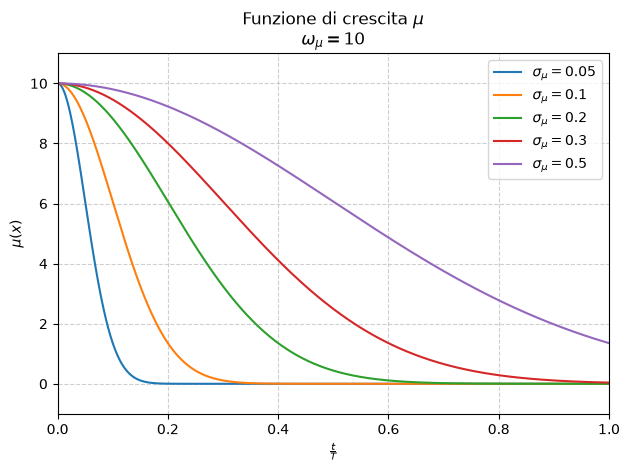

In [ ]:
for sigma in [0.05, 0.1, 0.2, 0.3, 0.5]:
    y = mu(x, omega, sigma)
    plt.plot(x, y, label = r'$\sigma_\mu = ' + str(sigma) + r'$')

plt.xlim(0, 1)
plt.ylim(-1, omega + 1)

save_plot(
    "mu_sigma",
    r"Funzione di crescita $\mu$" + "\n" + r"$\omega_\mu = " + str(omega) + r"$",
    r"$\frac{t}{T}$",
    r"$\mu(x)$",
    "upper right"
)

# Funzione di abbandono

In [ ]:
def nu(x: Array, beta: float, sigma: float) -> Array:
    return beta * np.exp(- ((x - 1) ** 2) / (2 * sigma ** 2))

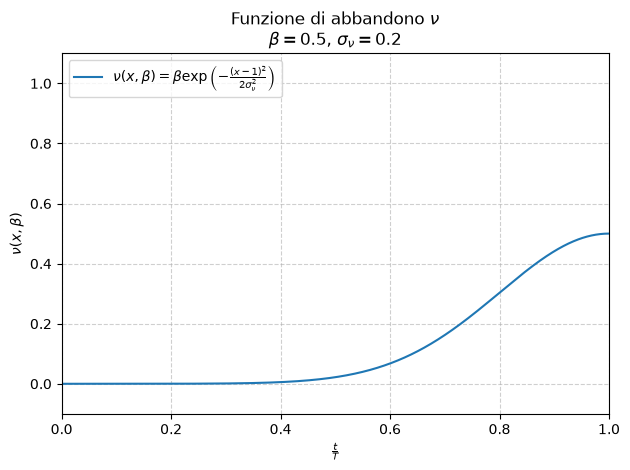

In [ ]:
beta: float = 0.5
sigma = 0.2

plt.plot(x, nu(x, beta, sigma), label = r'$\nu(x, \beta) = \beta \exp\left(-\frac{{(x - 1)}^2}{2 \sigma_\nu^2}\right)$')

plt.xlim(0, 1)
plt.ylim(-0.1, 1.1)

save_plot(
    "nu",
    r"Funzione di abbandono $\nu$" + "\n" + r"$\beta = " + str(beta) + r"$, $\sigma_\nu = " + str(sigma) + r"$",
    r"$\frac{t}{T}$",
    r"$\nu(x, \beta)$",
    "upper left"
)

# Funzione di infortunio

In [ ]:
def lam(
        f_f: Array,
        f_p: float,
        d: float,
        gamma: float,
        omega_f: float,
        omega_p: float,
        omega_d: float,
        b: float
    ) -> Array:
    return gamma / (1 + np.exp(- omega_f * f_f - omega_p * f_p - omega_d * d + b))

## Andamento in funzione della fatica fisica $f_f$

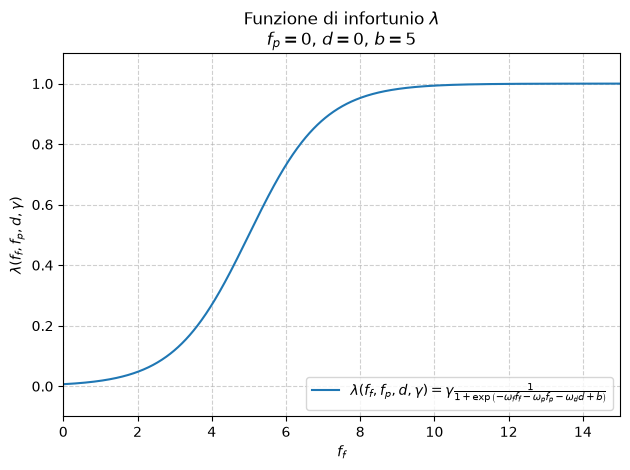

In [ ]:
fatigue: Array = np.linspace(0, 15, 1000)

f_p: float = 0
d: float = 0
gamma: float = 1
omega_f: float = 1
omega_p: float = 1
omega_d: float = 1
b: float = 5

plt.plot(
    fatigue, lam(fatigue, f_p, d, gamma, omega_f, omega_p, omega_d, b),
    label = r'$\lambda(f_f, f_p, d, \gamma) = \gamma \frac{1}{1 + \exp\left(-\omega_f f_f - \omega_p f_p - \omega_d d + b\right)}$'
)

plt.xlim(0, 15)
plt.ylim(-0.1, 1.1)

save_plot(
    "lambda_ff",
    r"Funzione di infortunio $\lambda$" + "\n" + r"$f_p = " + str(f_p) + r"$, $d = " + str(d) + r"$, $b = " + str(b) + r"$",
    r"$f_f$",
    r"$\lambda(f_f, f_p, d, \gamma)$",
    "lower right"
)

# Funzioni di carico

Tre esempi di carico nelle prime dieci sedute: costante, periodico (randori, tecnica, riposo) e variabile (casuale).

In [ ]:
def constant_load(t: Sessions) -> Array:
    return np.repeat(0.7, len(t))


def periodic_load(t: Sessions) -> Array:
    return ((2 - t) % 3) / 2


def variable_load(t: Sessions) -> Array:
    # seme fisso, per ottenere sempre lo stesso grafico
    np.random.seed(0)
    return np.random.uniform(0, 1, len(t))


# nome usato nei titoli e nei file -> funzione di carico
LOADS: dict[str, Callable[[Sessions], Array]] = {
    "costante": constant_load,
    "periodico": periodic_load,
    "variabile": variable_load,
}

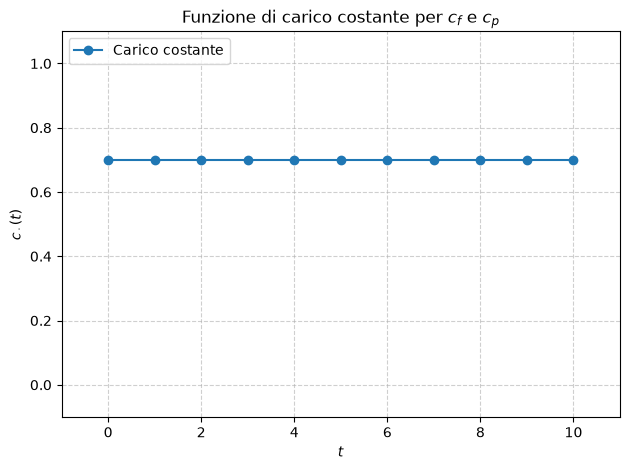

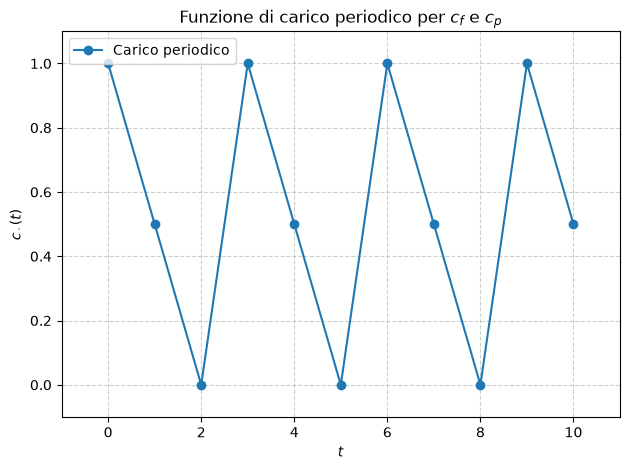

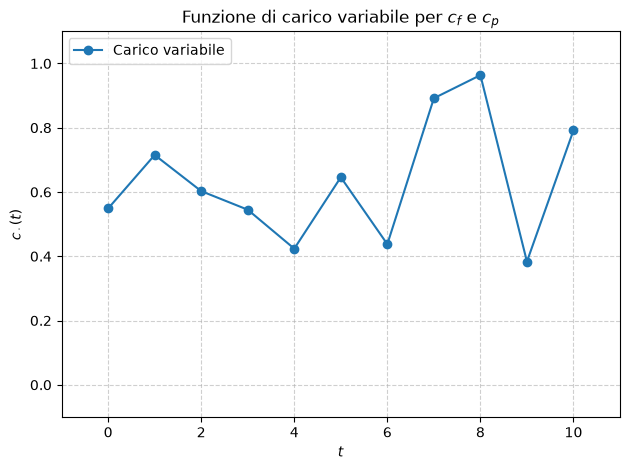

In [ ]:
sessions: Sessions = np.arange(0, 11, 1)

for name, load in LOADS.items():
    plt.plot(sessions, load(sessions), label = "Carico " + name, marker = "o")

    plt.xlim(-1, 11)
    plt.ylim(-0.1, 1.1)

    save_plot(
        "c_" + name,
        "Funzione di carico " + name + r" per $c_f$ e $c_p$",
        r"$t$",
        r"$c_\cdot(t)$",
        "upper left"
    )

# Funzione di recupero

In [ ]:
def r(t: Array, omega: float, sigma: float) -> Array:
    return 2 * omega / (1 + np.exp(sigma * t))

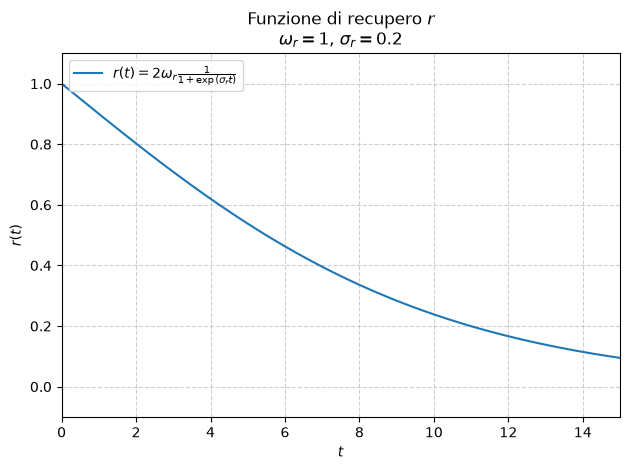

In [ ]:
t: Array = np.linspace(0, 15, 1000)

omega = 1
sigma = 0.2

plt.plot(t, r(t, omega, sigma), label = r"$r(t) = 2 \omega_r \frac{1}{1 + \exp\left(\sigma_r t\right)}$")

plt.xlim(0, 15)
plt.ylim(-0.1, 1.1)

save_plot(
    "r",
    r"Funzione di recupero $r$" + "\n" + r"$\omega_r = " + str(omega) + r"$, $\sigma_r = " + str(sigma) + r"$",
    r"$t$",
    r"$r(t)$",
    "upper left"
)